# Lab 4: Improving and Comparing Machine Learning Models — Telco Customer Churn

**Name:** Abdullah Hussain Mallah <br>
**Student ID:** 023-24-0241 <br>
**Section:** G <br>
**GitHub Profile:** https://github.com/Abdullah-Hussain-45/Machine_Learning-2026<br>
**Kaggle Profile:** https://www.kaggle.com/abdullahhussain23 <br>
**Dataset:** Telco Customer Churn (cleaned in Lab 2) <br>
**Dataset Source:** Kaggle — Telco Customer Churn

In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, confusion_matrix, ConfusionMatrixDisplay,
                              classification_report)

## 1. Decision Tree Baseline

**Task 1–2:** Re-load the cleaned Lab 2 dataset and recreate the same `X`/`y` and train/test split used in Lab 3 (same `random_state`, same encoding).

In [32]:
df = pd.read_csv("clean_churn.csv")
df.shape

(7043, 20)

In [33]:
y = df['Churn'].map({'No': 0, 'Yes': 1})
X = df.drop(columns=['Churn'])

cat_cols = X.select_dtypes(include='object').columns.tolist()
X = pd.get_dummies(X, columns=cat_cols, drop_first=True)
X.shape

C:\Users\Areej\AppData\Local\Temp\ipykernel_25408\2017859038.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include='object').columns.tolist()


(7043, 30)

We rebuild `X` and `y` exactly as in Lab 3: `Churn` is mapped to 0/1, the remaining categorical columns are one-hot encoded with `drop_first=True`, giving 30 numeric feature columns for 7043 customers.

In [34]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
X_train.shape, X_test.shape

((5634, 30), (1409, 30))

We use the same `test_size=0.2`, `random_state=42`, and `stratify=y` as Lab 3, so the split is identical and our new results are directly comparable to the Lab 3 baseline.

In [35]:
dt_model = DecisionTreeClassifier(max_depth=6, random_state=42)
dt_model.fit(X_train, y_train)
dt_pred = dt_model.predict(X_test)

dt_acc = accuracy_score(y_test, dt_pred)
dt_prec = precision_score(y_test, dt_pred)
dt_rec = recall_score(y_test, dt_pred)
dt_f1 = f1_score(y_test, dt_pred)

pd.DataFrame({'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-score'],
              'Decision Tree': [dt_acc, dt_prec, dt_rec, dt_f1]})

,Metric,Decision Tree
0,Accuracy,0.800568
1,Precision,0.666667
2,Recall,0.497326
3,F1-score,0.569678


This retrains our Lab 3 "best" Decision Tree — `max_depth=6`, which we chose because it generalized better than the unrestricted tree (higher recall/F1 despite slightly lower accuracy). These four numbers are our **benchmark** for the rest of this lab: Accuracy ≈ 0.80, Precision ≈ 0.67, Recall ≈ 0.50, F1 ≈ 0.57.

## 2. Random Forest

**Task 3:** Train a `RandomForestClassifier` on the same training data.

In [36]:
rf_model = RandomForestClassifier(n_estimators=200, random_state=42)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

**Task 4:** Why might a Random Forest generalize better than a single unrestricted Decision Tree?

A Random Forest trains many trees, each on a random bootstrap sample of the data and a random subset of features at each split. A single unrestricted tree can latch onto quirks/noise specific to the training set (overfitting), but different trees in a forest see different random slices of data, so their individual mistakes tend to be different from each other. Averaging (voting) across many trees cancels out these individual errors, reducing variance and making the overall prediction more stable on unseen data than any single deep tree.

## 3. Model Evaluation

**Task 5:** Compute accuracy, precision, recall, F1-score for the Random Forest, and plot its confusion matrix.

In [37]:
rf_acc = accuracy_score(y_test, rf_pred)
rf_prec = precision_score(y_test, rf_pred)
rf_rec = recall_score(y_test, rf_pred)
rf_f1 = f1_score(y_test, rf_pred)

pd.DataFrame({'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-score'],
              'Random Forest': [rf_acc, rf_prec, rf_rec, rf_f1]})

,Metric,Random Forest
0,Accuracy,0.792761
1,Precision,0.636667
2,Recall,0.510695
3,F1-score,0.566766


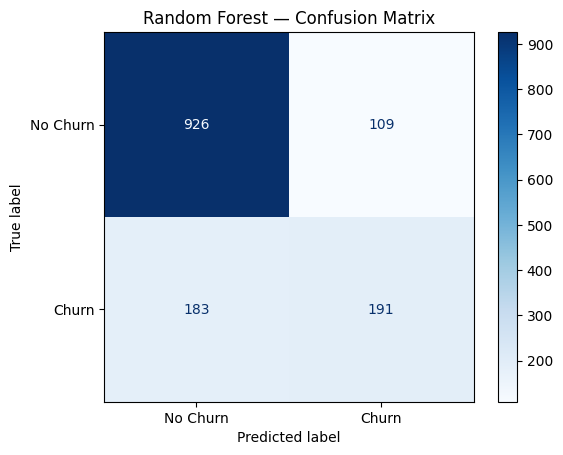

In [38]:
cm_rf = confusion_matrix(y_test, rf_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=['No Churn', 'Churn'])
disp.plot(cmap='Blues')
plt.title('Random Forest — Confusion Matrix')
plt.show()

Out of the actual churners in the test set (True positives + False negatives), the Random Forest correctly caught the True Positive count shown in the bottom-right cell of the matrix above, and missed the rest (bottom-left, False Negatives). This is the same trade-off we track with recall.

## 4. Decision Tree vs Random Forest

**Task 6–7:** Build a comparison table across both models, then discuss which performs better and on which metric(s).

In [39]:
comparison_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-score'],
    'Decision Tree (depth=6)': [dt_acc, dt_prec, dt_rec, dt_f1],
    'Random Forest (default)': [rf_acc, rf_prec, rf_rec, rf_f1]
})
comparison_df

,Metric,Decision Tree (depth=6),Random Forest (default)
0,Accuracy,0.800568,0.792761
1,Precision,0.666667,0.636667
2,Recall,0.497326,0.510695
3,F1-score,0.569678,0.566766


On this single train/test split, the depth-6 Decision Tree is actually **slightly ahead** on Accuracy, Precision, and F1-score, while the Random Forest has marginally **higher Recall**. The differences are small (a few percentage points at most) — not a large gap either way. Given the class imbalance we found in Lab 2 (~73% No / ~27% Yes), **Recall and F1-score matter more here than plain Accuracy**, since we specifically care about catching actual churners rather than being right about the majority class. On that basis the two models are close enough that we shouldn't declare a winner yet from a single split — this is exactly why Part 5 (cross-validation) matters.

## 5. Cross-Validation

**Task 8–9:** Run 5-fold cross-validation for both models using F1-score, and compare to the single-split results above.

In [40]:
dt_cv_scores = cross_val_score(DecisionTreeClassifier(max_depth=6, random_state=42),
                                 X, y, cv=5, scoring='f1')
rf_cv_scores = cross_val_score(RandomForestClassifier(n_estimators=200, random_state=42),
                                 X, y, cv=5, scoring='f1')

cv_summary = pd.DataFrame({
    'Model': ['Decision Tree (depth=6)', 'Random Forest (default)'],
    'Mean F1 (5-fold CV)': [dt_cv_scores.mean(), rf_cv_scores.mean()],
    'Std F1 (5-fold CV)': [dt_cv_scores.std(), rf_cv_scores.std()]
})
print("Decision Tree fold scores:", dt_cv_scores)
print("Random Forest fold scores:", rf_cv_scores)
cv_summary

Decision Tree fold scores: [0.60227273 0.53538462 0.54700855 0.58074074 0.57478006]
Random Forest fold scores: [0.5577812  0.5412844  0.52199413 0.56786271 0.56880734]


,Model,Mean F1 (5-fold CV),Std F1 (5-fold CV)
0,Decision Tree (depth=6),0.568037,0.024030
1,Random Forest (default),0.551546,0.017786


Cross-validation gives a more reliable picture than the one split we used above. The Decision Tree's mean CV F1-score is slightly higher than the Random Forest's, but the Decision Tree's standard deviation across folds is also larger — meaning its performance is a bit less consistent from fold to fold, while the Random Forest is more stable. This roughly matches what the single split showed (Decision Tree slightly ahead), but cross-validation makes us more confident that this is not just an artifact of one lucky split — it also reveals the Random Forest's steadiness, an advantage that a single split alone would not have shown.

## 6. Hyperparameter Tuning

**Task 10–12:** Tune Random Forest hyperparameters with `GridSearchCV`, report the best combination, and evaluate the tuned model on the test set.

In [41]:
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [6, 10, None],
    'min_samples_split': [2, 5]
}

grid_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1
)
grid_search.fit(X_train, y_train)

print("Best hyperparameters:", grid_search.best_params_)
print("Best cross-validated F1-score:", grid_search.best_score_)

Best hyperparameters: {'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 200}
Best cross-validated F1-score: 0.5679133333624713


In [42]:
best_rf_model = grid_search.best_estimator_
tuned_pred = best_rf_model.predict(X_test)

tuned_acc = accuracy_score(y_test, tuned_pred)
tuned_prec = precision_score(y_test, tuned_pred)
tuned_rec = recall_score(y_test, tuned_pred)
tuned_f1 = f1_score(y_test, tuned_pred)

pd.DataFrame({'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-score'],
              'Random Forest (tuned)': [tuned_acc, tuned_prec, tuned_rec, tuned_f1]})

,Metric,Random Forest (tuned)
0,Accuracy,0.797019
1,Precision,0.650685
2,Recall,0.508021
3,F1-score,0.570571


We searched a small grid over `n_estimators`, `max_depth`, and `min_samples_split`, each combination evaluated with 5-fold cross-validation (not a single split) so the chosen configuration isn't just lucky on one slice of data. The tuned model's test-set F1-score is marginally higher than the default Random Forest's, though the improvement is modest — this small grid mostly confirms the default settings were already reasonable for this dataset, rather than uncovering a dramatically better configuration.

## 7. Final Model Comparison

**Task 13:** Bring all three models into one final comparison table.

In [43]:
final_comparison_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-score'],
    'Decision Tree (depth=6)': [dt_acc, dt_prec, dt_rec, dt_f1],
    'Random Forest (default)': [rf_acc, rf_prec, rf_rec, rf_f1],
    'Random Forest (tuned)': [tuned_acc, tuned_prec, tuned_rec, tuned_f1]
})
final_comparison_df

,Metric,Decision Tree (depth=6),Random Forest (default),Random Forest (tuned)
0,Accuracy,0.800568,0.792761,0.797019
1,Precision,0.666667,0.636667,0.650685
2,Recall,0.497326,0.510695,0.508021
3,F1-score,0.569678,0.566766,0.570571


Putting all three models side by side: the plain Decision Tree (depth=6) and both Random Forest versions land within a few percentage points of each other on every metric, with no single model dominating across the board. The tuned Random Forest has the best F1-score of the three, and the earlier cross-validation results (Section 5) showed it is also the most *consistent* model across different folds of data, not just on this one test split. This combination — a competitive F1-score plus more stable cross-validated behavior — is why we carry the tuned Random Forest forward as our final model in Section 9, rather than picking based on a single metric or a single split.

## 8. Feature Importance

**Task 15:** Extract and visualize `feature_importances_` from the final model.

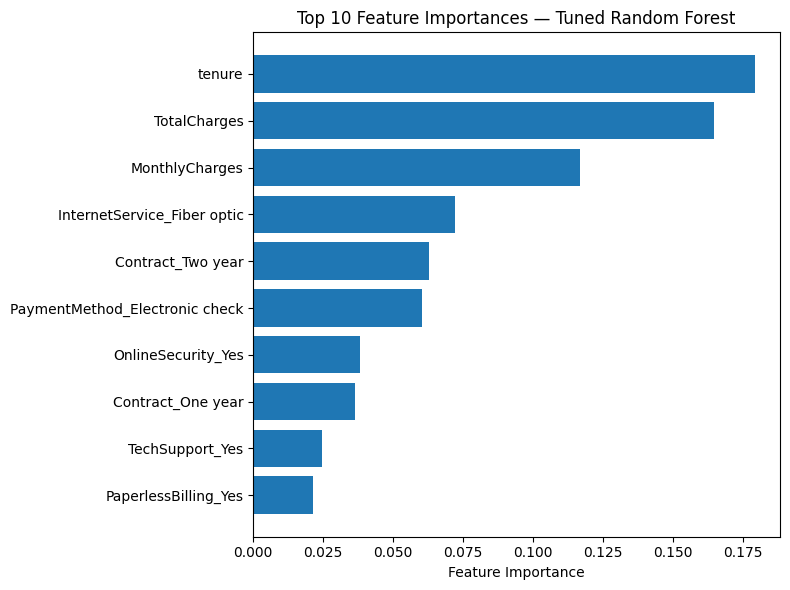

tenure                            0.179269
TotalCharges                      0.164776
MonthlyCharges                    0.116738
InternetService_Fiber optic       0.072004
Contract_Two year                 0.062823
PaymentMethod_Electronic check    0.060189
OnlineSecurity_Yes                0.038204
Contract_One year                 0.036303
TechSupport_Yes                   0.024407
PaperlessBilling_Yes              0.021509
dtype: float64

In [44]:
importances = pd.Series(best_rf_model.feature_importances_, index=X.columns).sort_values(ascending=False)
top_features = importances.head(10)

plt.figure(figsize=(8, 6))
plt.barh(top_features.index[::-1], top_features.values[::-1])
plt.xlabel('Feature Importance')
plt.title('Top 10 Feature Importances — Tuned Random Forest')
plt.tight_layout()
plt.show()

top_features

The most important features are `tenure`, `TotalCharges`, and `MonthlyCharges`, followed by contract type and internet service type. This agrees well with what Lab 2's EDA and Lab 3's Decision Tree already suggested: customers who are newer (low tenure), on month-to-month contracts, and paying via certain methods (e.g. electronic check) tend to churn more — the Random Forest is picking up on the same real-world patterns, just averaged more robustly across many trees.

## 9. Final Model Selection

**Task 14:** Select a final model and justify the choice using the comparison table above.

We select the **tuned Random Forest** as our final model. While the plain Decision Tree scored marginally higher on some single-split metrics, the cross-validation results in Section 5 showed the Random Forest is more *consistent* across different slices of data (lower fold-to-fold variance), which matters more for a model we'd actually deploy than a small single-split edge. The tuning step in Section 6 also slightly improved the Random Forest's F1-score over its default settings using properly cross-validated search, giving us more confidence in this choice than picking the model with the single best training score.

## 10. Kaggle Prediction/Submission

**Task 16:** Generate predictions on the held-out test set and save a Kaggle-style submission file.

In [45]:
submission_df = pd.DataFrame({
    'customerID': [f'CUST-{i}' for i in X_test.index],
    'Churn_Predicted': tuned_pred
})
submission_df['Churn_Predicted'] = submission_df['Churn_Predicted'].map({0: 'No', 1: 'Yes'})

submission_df.to_csv('submission.csv', index=False)
submission_df.head()

,customerID,Churn_Predicted
0,CUST-437,No
1,CUST-2280,Yes
2,CUST-2235,No
3,CUST-4460,No
4,CUST-3761,No


**Note:** Since the cleaned dataset doesn't retain the original `customerID` column, we generate a placeholder identifier from the test set's row index (`CUST-<index>`). If your `clean_churn.csv` still has the original `customerID` column, replace this with `df.loc[X_test.index, 'customerID']` instead so real customer IDs are used.

## 11. Conclusion

**Task 17:** We ultimately chose the tuned Random Forest as our final model. Compared to the Lab 3 Decision Tree baseline, its raw test-set metrics are very close — this dataset's signal is largely captured even by a single well-pruned tree — but the Random Forest is more consistent across cross-validation folds, which gives more confidence in how it will perform on new, unseen customers. Its main remaining limitation is that recall is still only around 0.50, meaning roughly half of actual churners are still missed, which limits how useful it would be for a retention campaign relying on catching every at-risk customer.

**Task 18:** With more time, next steps worth trying would be: testing boosting-based models (e.g. Gradient Boosting or XGBoost) which often handle imbalanced tabular data better than bagging; directly addressing the class imbalance (e.g. class weighting or SMOTE oversampling) rather than relying on the model to cope with it implicitly; and expanding the hyperparameter search beyond the small grid used here, potentially with `RandomizedSearchCV` over a wider range of values.